# 02 Baseline of normal DNS (slice 2)

Goal of this notebook: learn what normal DNS looks like in `dns.log`, before building features. Questions: record types and response codes, name length and randomness, busy domains and unique names per domain, query rate, benign look-alikes of the tunnel, and whether the benign traffic is stable over time.

Works on `dns.log` only. Labels from `data/labels.csv` are joined by `row_id` **before** any sorting.

In [2]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
if not (RAW / "dns.log").exists():       # Canvas download keeps the files in a "Case 1" folder
    RAW = RAW / "Case 1"

# Column names come from Zeek's own #fields line
with open(RAW / "dns.log", encoding="latin-1") as f:
    COLS = next(l for l in f if l.startswith("#fields")).rstrip("\n").split("\t")[1:]

df = pd.read_csv(RAW / "dns.log", sep="\t", comment="#", names=COLS,
                 na_values=["-"], keep_default_na=False, encoding="latin-1")
df.index.name = "row_id"                  # 0-based file order: do NOT sort before the join

# Join labels first, sort never (or only afterwards, on a copy)
df = df.join(pd.read_csv(ROOT / "data" / "labels.csv", index_col="row_id"))
assert df["label"].notna().all() and len(df) == 3645

# Derived columns used throughout the notebook
df["dt"] = pd.to_datetime(df["ts"], unit="s")
# Zeek writes each non-printable byte as \xNN (4 characters); count it as the 1 byte it was on the wire
df["name_bytes"] = df["query"].map(lambda q: len(re.sub(r"\\x[0-9A-Fa-f]{2}", "X", q)))
df["parent"] = df["query"].str.split(".").str[-2:].str.join(".")   # naive, replace with a suffix rule in features.py

benign = df[df["label"] == "benign"]
print(df.shape, df["dt"].min(), "to", df["dt"].max())
print(df["label"].value_counts())

(3645, 28) 2023-01-07 17:35:53.449249983 to 2023-01-07 19:10:10.316880941
label
benign    3201
tunnel     444
Name: count, dtype: int64


In [ ]:
# Check: longest names per label (expect about 252 for tunnel, 103 for benign)
df.groupby("label")["name_bytes"].max()

label
benign    103
tunnel    252
Name: name_bytes, dtype: int64

## 1. What is normal made of: record types and response codes

Tunnel rows are shown next to benign ones for contrast. Counts, not shares, because the benign client is the only normal traffic we have.

In [5]:
display(pd.crosstab(df["qtype_name"], df["label"]))
display(pd.crosstab(df["rcode_name"].fillna("(no answer)"), df["label"]))

label,benign,tunnel
qtype_name,,
A,1199,0
AAAA,882,0
HTTPS,1110,0
NULL,0,444
PTR,7,0
SVCB,3,0


label,benign,tunnel
rcode_name,,
(no answer),1,20
NOERROR,3189,424
NXDOMAIN,11,0


## 2. Shape of the names

Per query: name length in bytes, number of labels, longest label, and Shannon entropy (bits per character) of the part left of the parent domain. Zeek's `\xNN` escapes are turned back into single bytes first, so these are wire values. Names with no subdomain (for example `google.com`) get entropy 0.

In [6]:
from collections import Counter

def to_bytes(q):
    # \xNN escapes back to the original byte
    return re.sub(r"\\x([0-9A-Fa-f]{2})", lambda m: chr(int(m.group(1), 16)), q).encode("latin-1")

def entropy(b):
    if not b:
        return 0.0
    p = np.array(list(Counter(b).values())) / len(b)
    return float(-(p * np.log2(p)).sum())

def shape(q):
    labels = to_bytes(q).rstrip(b".").split(b".")
    return pd.Series({"n_labels": len(labels),
                      "longest_label": max(map(len, labels)),
                      "entropy": entropy(b".".join(labels[:-2]))})

df = df.join(df["query"].apply(shape))
benign = df[df["label"] == "benign"]
cols = ["name_bytes", "n_labels", "longest_label", "entropy"]
display(df.groupby("label")[cols].describe(percentiles=[.5, .95, .99]).T.round(2))

label                 benign  tunnel
name_bytes    count  3201.00  444.00
              mean     22.78   46.83
              std      10.55   67.20
              min       4.00   17.00
              50%      20.00   19.00
              95%      51.00  252.00
              99%      63.00  252.00
              max     103.00  252.00
n_labels      count  3201.00  444.00
              mean      3.44    3.44
              std       0.91    1.14
              min       2.00    3.00
              50%       3.00    3.00
              95%       6.00    7.00
              99%       6.00    7.00
              max       9.00    7.00
longest_label count  3201.00  444.00
              mean     10.01   17.97
              std       5.15   20.63
              min       2.00    6.00
              50%       9.00    8.00
              95%      17.00   62.00
              99%      26.00   62.00
              max      57.00   62.00
entropy       count  3201.00  444.00
              mean      2.32    3.01
              std       1.22    1.03
              min      -0.00    1.82
              50%       2.52    2.75
              95%       4.32    5.62
              99%       4.33    6.23
              max       4.53    6.30

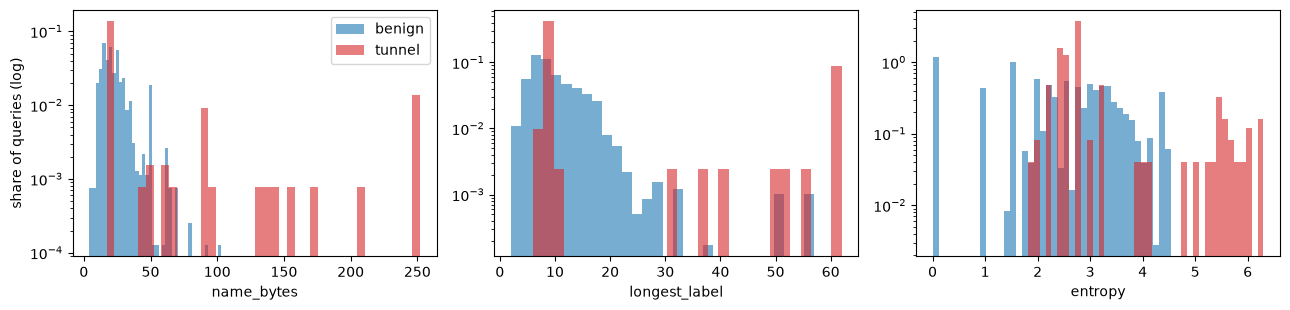

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, col, bins in zip(axes, ["name_bytes", "longest_label", "entropy"], [40, 30, 40]):
    for lab, color in [("benign", "tab:blue"), ("tunnel", "tab:red")]:
        ax.hist(df.loc[df.label == lab, col], bins=bins, alpha=.6, color=color, label=lab, density=True)
    ax.set_xlabel(col); ax.set_yscale("log")
axes[0].set_ylabel("share of queries (log)"); axes[0].legend()
plt.tight_layout(); plt.show()

## 3. Benign look-alikes

The benign names that come closest to the tunnel on length and randomness. These are the likely false positives later.

In [8]:
show = ["query", "qtype_name", "name_bytes", "longest_label", "entropy"]
print("longest benign names"); display(benign.nlargest(8, "name_bytes")[show])
print("highest-entropy benign names"); display(benign.nlargest(8, "entropy")[show])

longest benign names


,query,qtype_name,name_bytes,longest_label,entropy
row_id,,,,,
1122,ic3-unified-presence-service-presence.westeuro...,HTTPS,103,37.0,3.789438
3324,_9573._https.pe80430c73-cc46-4682-a0b2-e867b33...,HTTPS,93,51.0,4.471761
3322,pe80430c73-cc46-4682-a0b2-e867b33316be-54-90-1...,A,80,51.0,4.324247
3323,pe80430c73-cc46-4682-a0b2-e867b33316be-54-90-1...,AAAA,80,51.0,4.324247
2983,146-241-85-122_s-78-134-83-209_ts-1673117514-c...,AAAA,70,57.0,3.933963
2984,146-241-85-122_s-78-134-83-209_ts-1673117514-c...,HTTPS,70,57.0,3.933963
2985,146-241-85-122_s-78-134-83-209_ts-1673117514-c...,AAAA,70,57.0,3.933963
2986,146-241-85-122_s-78-134-83-209_ts-1673117514-c...,HTTPS,70,57.0,3.933963


highest-entropy benign names


,query,qtype_name,name_bytes,longest_label,entropy
row_id,,,,,
2977,slyvk6sqincawy5zx5fa-pw2lcn-4b611d2b3-clientns...,A,63,50.0,4.533661
2981,slyvk6sqincawy5zx5fa-pw2lcn-4b611d2b3-clientns...,AAAA,63,50.0,4.533661
2982,slyvk6sqincawy5zx5fa-pw2lcn-4b611d2b3-clientns...,HTTPS,63,50.0,4.533661
3324,_9573._https.pe80430c73-cc46-4682-a0b2-e867b33...,HTTPS,93,51.0,4.471761
52,188224-ipv4v6e.farm.dprodmgd104.sharepointonli...,A,63,16.0,4.468919
53,188224-ipv4v6e.farm.dprodmgd104.sharepointonli...,HTTPS,63,16.0,4.468919
102,188224-ipv4v6e.farm.dprodmgd104.sharepointonli...,HTTPS,63,16.0,4.468919
103,188224-ipv4v6e.farm.dprodmgd104.sharepointonli...,A,63,16.0,4.468919


## 4. Busy domains and unique names per domain

The tunnel's strongest property is many different names under one domain. Here is what that looks like for normal domains. The parent domain is the naive last two labels (see the check at the end of this section).

In [9]:
dom = (df.groupby(["label", "parent"])
         .agg(queries=("query", "size"), unique_names=("query", "nunique"),
              mean_bytes=("name_bytes", "mean"), max_bytes=("name_bytes", "max"))
         .round(1).reset_index())
print("top benign domains by unique names")
display(dom[dom.label == "benign"].nlargest(10, "unique_names").drop(columns="label"))
print("tunnel domain")
display(dom[dom.label == "tunnel"].drop(columns="label"))
print("benign domains:", (dom.label == "benign").sum())

top benign domains by unique names


,parent,queries,unique_names,mean_bytes,max_bytes
232,yahoo.com,191,35,18.6,34
105,google.com,163,27,17.0,48
234,yahoodns.net,60,20,32.1,37
36,azure.com,25,17,47.1,59
30,apple.com,28,14,18.5,30
113,googlevideo.com,42,13,33.4,35
207,taboola.com,39,12,18.8,25
60,cnn.com,65,11,14.8,21
107,googleapis.com,102,11,24.1,31
5,aaplimg.com,16,9,26.3,35


tunnel domain


,parent,queries,unique_names,mean_bytes,max_bytes
244,pirate.sea,444,222,46.8,252


benign domains: 244


In [10]:
# Same idea per one-minute window: unique names per domain per minute
df["minute"] = df["dt"].dt.floor("1min")
pm = (df.groupby(["label", "parent", "minute"])["query"]
        .agg(queries="size", unique_names="nunique").reset_index())
b_pm = pm[pm.label == "benign"]
print("busiest benign (domain, minute) pairs by unique names")
display(b_pm.nlargest(8, "unique_names").drop(columns="label"))
print("tunnel, per minute")
display(pm[pm.label == "tunnel"].drop(columns="label"))
print("benign (domain, minute) pairs:", len(b_pm), "| with >= 10 unique names:", (b_pm.unique_names >= 10).sum(),
      "| >= 20:", (b_pm.unique_names >= 20).sum(), "| max:", b_pm.unique_names.max())

busiest benign (domain, minute) pairs by unique names


,parent,minute,queries,unique_names
686,yahoo.com,2023-01-07 18:50:00,111,27
265,google.com,2023-01-07 18:09:00,48,16
687,yahoo.com,2023-01-07 18:51:00,62,14
644,taboola.com,2023-01-07 18:12:00,36,12
154,cnn.com,2023-01-07 18:11:00,35,10
323,googlevideo.com,2023-01-07 18:51:00,30,10
177,decrypt.co,2023-01-07 18:52:00,22,7
268,google.com,2023-01-07 18:12:00,23,7


tunnel, per minute


,parent,minute,queries,unique_names
711,pirate.sea,2023-01-07 18:04:00,221,221
712,pirate.sea,2023-01-07 18:05:00,1,1
713,pirate.sea,2023-01-07 18:50:00,26,26
714,pirate.sea,2023-01-07 18:51:00,196,196


benign (domain, minute) pairs: 711 | with >= 10 unique names: 6 | >= 20: 1 | max: 27


In [11]:
# Where the naive parent domain breaks: names under a country-code second level (co.uk, com.au, ...)
cc = df.loc[df["parent"].str.split(".").str[-1].str.len() == 2, "parent"].value_counts()
print("parents ending in a 2-letter TLD:"); display(cc.to_frame("queries"))

parents ending in a 2-letter TLD:


,queries
parent,
co.uk,63
cnn.io,37
spot.im,27
decrypt.co,22
google.it,21
pubgenius.io,7
ethicalads.io,6
clean.gg,6
sophi.io,6


## 5. Query rate over time

Does volume separate the classes?

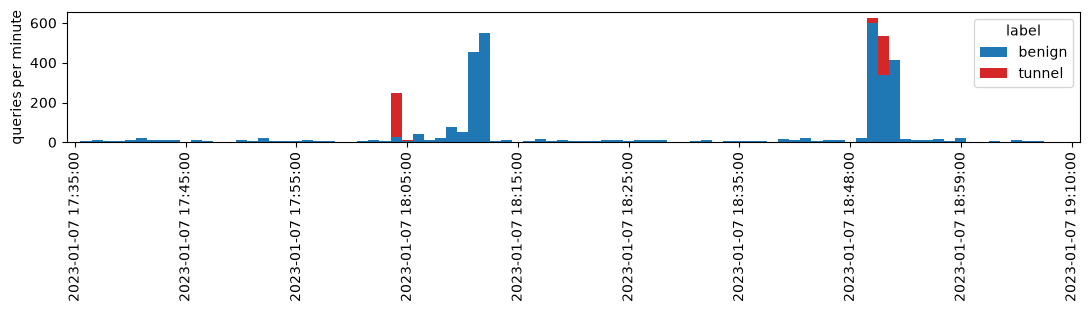

peak queries per minute:


,peak
label,
benign,598
tunnel,221


busiest benign minutes:


,benign queries
minute,
2023-01-07 18:50:00,598
2023-01-07 18:12:00,551
2023-01-07 18:11:00,452
2023-01-07 18:52:00,415
2023-01-07 18:51:00,337


In [12]:
rate = df.groupby(["minute", "label"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(11, 3.2))
rate.plot(ax=ax, kind="bar", stacked=True, width=1.0, color=["tab:blue", "tab:red"])
ax.set_xticks(ax.get_xticks()[::10]); ax.set_xlabel(""); ax.set_ylabel("queries per minute")
plt.tight_layout(); plt.show()
print("peak queries per minute:"); display(rate.max().to_frame("peak"))
print("busiest benign minutes:"); display(rate["benign"].nlargest(5).to_frame("benign queries"))

## 6. Stability: first half against second half of the benign traffic

Split at the median timestamp. If normal is stable, the two halves should look alike. This is a rough check on 3,201 queries and 95 minutes, not a proof.

In [13]:
from scipy.stats import ks_2samp
cut = benign["dt"].median()
first, second = benign[benign["dt"] < cut], benign[benign["dt"] >= cut]
print("split at", cut, "| rows:", len(first), "/", len(second))

summary = pd.DataFrame({
    "first half": [first["name_bytes"].median(), first["name_bytes"].quantile(.95), first["entropy"].median(),
                   first["entropy"].quantile(.95), first["query"].nunique(), first["parent"].nunique()],
    "second half": [second["name_bytes"].median(), second["name_bytes"].quantile(.95), second["entropy"].median(),
                    second["entropy"].quantile(.95), second["query"].nunique(), second["parent"].nunique()],
}, index=["name_bytes median", "name_bytes 95th pct", "entropy median", "entropy 95th pct",
          "unique names", "unique parent domains"]).round(2)
display(summary)
display(pd.concat([first["qtype_name"].value_counts(normalize=True).rename("first half"),
                   second["qtype_name"].value_counts(normalize=True).rename("second half")], axis=1).round(3))
for col in ["name_bytes", "entropy", "longest_label"]:
    r = ks_2samp(first[col], second[col])
    print(f"KS test {col}: statistic {r.statistic:.3f}, p = {r.pvalue:.3g}")
shared = set(first["parent"]) & set(second["parent"])
print("parent domains in both halves:", len(shared), "of", len(set(first["parent"]) | set(second["parent"])))

split at 2023-01-07 18:31:53.296651008 | rows: 1601 / 1600


,first half,second half
name_bytes median,20.00,20.00
name_bytes 95th pct,51.00,45.00
entropy median,2.52,2.52
entropy 95th pct,4.33,4.14
unique names,427.00,390.00
unique parent domains,169.00,161.00


,first half,second half
qtype_name,,
A,0.384,0.366
HTTPS,0.350,0.344
AAAA,0.262,0.289
PTR,0.003,0.001
SVCB,0.001,0.001


KS test name_bytes: statistic 0.043, p = 0.0952
KS test entropy: statistic 0.028, p = 0.533
KS test longest_label: statistic 0.052, p = 0.0256
parent domains in both halves: 86 of 244


## Observations (step 1)

- **Record types:** benign uses A (1,199), AAAA (882), HTTPS (1,110), and a few PTR (7) and SVCB (3). NULL is used only by the tunnel (444). Record type alone separates the classes, but only because the tunnel is iodine in NULL mode; a tunnel that falls back to TXT, CNAME or A would not show it.
- **Response codes:** all 11 NXDOMAIN rows are benign; no tunnel row has one. 21 queries have no answer (20 tunnel, 1 benign).
- **Name length (bytes):** benign median 20, 95th percentile 51, max 103. Tunnel median 19 (the pings), 95th percentile 252. The median hides the split inside the tunnel: the long names are the data and probe queries only.
- **Entropy:** benign median 2.52, tunnel median 2.75, again almost the same. At the top end the tunnel reaches 6.3 bits per character against 4.53 for benign.
- **Number of labels:** identical shape (median 3 for both). Not useful on its own.
- **Benign look-alikes:** 16 benign rows are longer than 63 bytes and 12 have a label over 40 bytes. 201 benign rows have entropy above 4 bits (against 56 tunnel rows), so an entropy threshold alone flags many benign queries. The long and random-looking benign names are CDN and cloud names, for example `...cosmic.office.net` (103 bytes), `pe80430c73-cc46-...fastcast.semfs.engsvc.go.com`, `146-241-85-122_s-78-134-83-209_ts-...akamaihd.net` and `slyvk6sqincawy5zx5fa-...akamaihd.net`. Several of them are repeated as A, AAAA and HTTPS lookups.
- **Repetition:** benign traffic has only 670 distinct names in 3,201 queries (the same name is asked as A, AAAA and HTTPS, and repeated). The tunnel has 222 distinct names in 444 queries because of the replay. Unique names per domain, not per-query shape, is where the classes differ most.

### Domains, rate and stability (sections 4 to 6)

- **Unique names per domain:** the benign domain with the most unique names is `yahoo.com` with 35; then `google.com` (27), `yahoodns.net` (20), `azure.com` (17). `pirate.sea` has 222, about 6 times more. 244 benign domains in total.
- **Per minute:** the busiest benign (domain, minute) pair has 27 unique names (`yahoo.com`, 18:50); only 6 of 711 pairs reach 10 and only 1 reaches 20. The tunnel has 221 in one minute. **But the second burst is split by the fixed one-minute bins: 26 names in the 18:50 bin and 196 in the 18:51 bin.** The first of those (26) is barely above the benign maximum. A fixed window makes the feature depend on where the bin edge falls, so the feature should use a rolling (sliding) window.
- **Query rate:** the benign client peaks at 598 queries per minute (18:50, the same minute the second tunnel burst starts), the tunnel at 221. Volume points at the wrong client.
- **Naive parent domain:** it breaks on `co.uk` (63 queries lumped under one "domain"). The other two-letter endings in the list (`cnn.io`, `spot.im`, `decrypt.co`, ...) are real registered domains and are fine. `features.py` needs a public suffix list.
- **Stability:** the two halves of the benign traffic look alike (name length median 20 and entropy median 2.52 in both; record type mix within a few points; KS tests do not reject for name length and entropy, longest label differs slightly with p = 0.026). Only 86 of 244 parent domains appear in both halves, so any feature that depends on the identity of a domain would not carry over. Features built on counts and shapes do.